# Punto 5 (0.8) — CMY: lineal a trozos sobre Amarillo

Aplique la transformación a su imagen RGB.

- Paso 1. Convierta su imagen RGB al espacio CMY
- Paso 2. Aplique una transformación lineal a trozos al componente Amarillo. Con r1=80, r2=210, s1=60 y s2=120
- Paso 3. Reconstruya la imagen en CMY con el componente Amarillo modificado en el paso 2 y los demás componentes sin modificar
- Paso 4. Convierta la imagen obtenida en el Paso 3 al espacio RGB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import sys
sys.path.append("..")
from colorspaces import rgb_to_cmy, cmy_to_rgb


## Imagen original RGB

(1024, 1024, 3) uint8


(np.float64(-0.5), np.float64(1023.5), np.float64(1023.5), np.float64(-0.5))

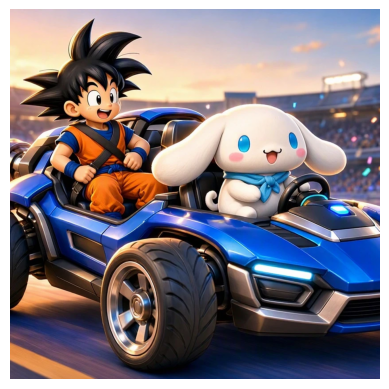

In [2]:
img = np.array(Image.open("../images/mi_imagen.png").convert("RGB"))
print(img.shape, img.dtype)

plt.figure()
plt.imshow(img)
plt.axis("off")


## Paso 1 — RGB a CMY

In [3]:
cmy = rgb_to_cmy(img)


## Paso 2 — Lineal a trozos sobre Amarillo

In [4]:
amarillo = np.round(cmy[..., 2] * 255).astype(np.uint8)

amarillo_mod = np.zeros_like(amarillo)
cv2.intensity_transform.contrastStretching(amarillo, amarillo_mod, 80, 60, 210, 120)


## Pasos 3 y 4 — Reconstrucción y vuelta a RGB

In [5]:
cmy_mod = cmy.copy()
cmy_mod[..., 2] = amarillo_mod / 255.0
resultado = cmy_to_rgb(cmy_mod)

Image.fromarray(resultado).save("../results/punto5_transformada.png")


## Comparación original vs transformada

Complete la tabla con la imagen original RGB y la imagen transformada.

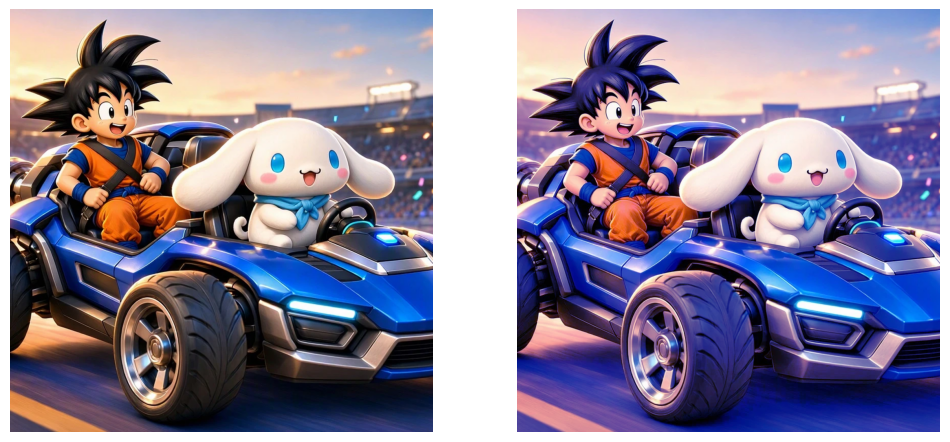

In [6]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(resultado)
plt.axis("off")
plt.savefig("../results/punto5_comparacion.png", bbox_inches="tight", pad_inches=0)
